In [78]:
from sklearn.datasets import load_iris
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score , confusion_matrix, classification_report


datf = load_iris(as_frame = True)
df = datf.frame
print(df.columns)
print(df.head())

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  target
0                5.1               3.5  ...               0.2       0
1                4.9               3.0  ...               0.2       0
2                4.7               3.2  ...               0.2       0
3                4.6               3.1  ...               0.2       0
4                5.0               3.6  ...               0.2       0

[5 rows x 5 columns]


In [79]:
X = datf.data
y = datf.target
print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [80]:
X_train , X_test , y_train , y_test = train_test_split( X , y , test_size = 0.2 , random_state = 42)

In [81]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [82]:
archs = [(5,), (10,), (20,), (10,5), (20,10)]
accs = []
for i in archs:
  model = MLPClassifier(
      hidden_layer_sizes = i,
      max_iter = 1000,
      random_state = 42,
      activation = 'relu'

  )
  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  acc = accuracy_score(y_test, pred)
  prec = precision_score(y_test, pred, average='weighted')
  rec = recall_score(y_test, pred, average='weighted')
  f1 = f1_score(y_test, pred, average='weighted')
  accs.append(acc)

  print(f"Accuracy: {acc}")
  print(f"Precision: {prec}")
  print(f"Recall: {rec}")
  print(f"F1 Score: {f1}")


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [83]:
bestind = accs.index(max(accs))
bestk = archs[bestind]

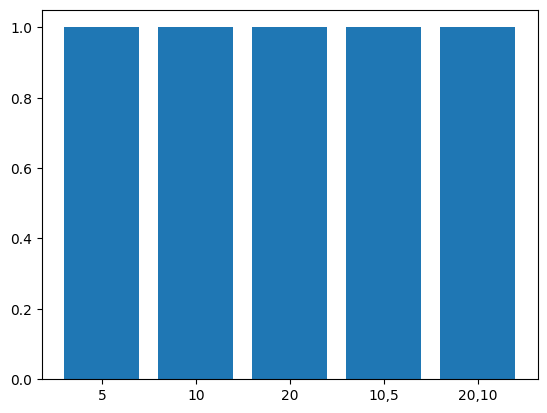

In [85]:
import matplotlib.pyplot as plt
names = ['5','10','20','10,5','20,10']
plt.bar(names,accs)
plt.show()


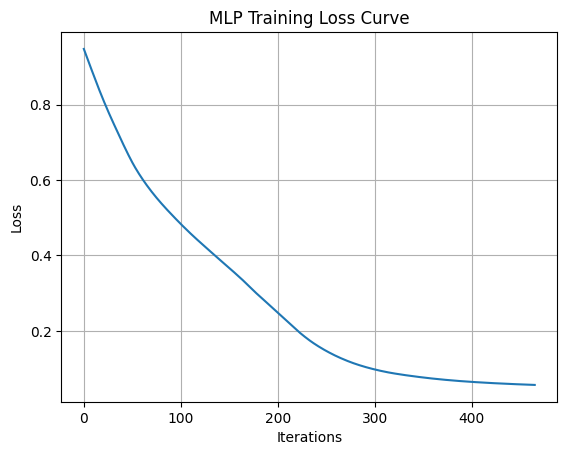

In [86]:
plt.plot(model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curve")
plt.grid(True)
plt.show()